# Module 3 (ICSE): evaluation of entity extraction and clinical flags

**Nora MedLink, BS Data Science FYP.** Synthetic data only: no real patient data is used anywhere in this notebook.

What is measured:

1. **FE-1 entity extraction**: precision, recall and F1 per entity type, for the rules and knowledge base alone and with BioBERT suggestions added (scikit-learn metrics).
2. **Negation**: a confusion matrix of "negated or not" for the conditions both found and expected.
3. **A hand-written set** of harder phrasing (the generated set shares its author with the extractor, so it flatters the rules).
4. **FE-3 flags**: flags built from what the extractor read against flags built from the ground truth.
5. **OCR**: test values read right, wrong or missed per OCR engine (from the OCR benchmark).

Run from the repository root with the backend virtualenv (`backend/requirements-ds.txt`). BioBERT runs offline from its local cache.

In [1]:
import os, sys, json, csv
from pathlib import Path
from collections import Counter

os.environ.setdefault("HF_HUB_OFFLINE", "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "scripts" / "icse_bench")]

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

from services.icse.entities import extract_entities
from services.icse.flags import build_flags, printed_date
from services.biobert_service import _run_biobert
import generate_patients
from benchmark_flags import truth_entity, flag_keys

pd.set_option("display.precision", 3)
TYPES = ["test_result", "vital", "medication", "condition", "family_history", "allergy", "allergy_status"]

## 1. Data: synthetic patients

The generator writes 12 patients with 3-4 reports each (clinic notes, discharge summaries and lab reports over time) and the exact ground truth for every report.

In [2]:
generate_patients.main()
reports = []
for folder in sorted((ROOT / "icse_samples").glob("icse-p*")):
    for item in json.loads((folder / "entities.json").read_text(encoding="utf-8")):
        reports.append({"patient": folder.name, **item, "text": (folder / item["file"]).read_text(encoding="utf-8")})
summary = pd.DataFrame(reports).groupby("kind").agg(reports=("file", "count"), entities=("entities", lambda e: sum(map(len, e))))
summary

Wrote 42 reports for 12 synthetic patients to C:\Users\LENOVO\Desktop\noramedlink\icse_samples


,reports,entities
kind,,
clinic,12,157
discharge,6,76
lab,24,168


In [3]:
def key(entity):
    kind, name = entity["type"], str(entity["name"]).lower()
    if kind in ("test_result", "vital"):
        return kind, name, entity.get("value")
    if kind == "medication":
        return kind, name, entity.get("status", "mentioned")
    if kind == "condition":
        return kind, name, bool(entity.get("negated"))
    return kind, name

def biobert(text):
    try:
        return _run_biobert(" ".join(text.split()))
    except Exception as exc:  # no local model: suggestions are simply absent
        print("BioBERT unavailable:", type(exc).__name__)
        return []

rows = []
for r in reports:
    expected = Counter(key(e) for e in r["entities"] if e["type"] in TYPES)
    rules = Counter(key(e) for e in extract_entities(r["text"]) if e["type"] in TYPES)
    model = Counter(key(e) for e in extract_entities(r["text"], biobert(r["text"])) if e["type"] in TYPES)
    for item in expected | rules | model:
        rows.append({"report": f"{r['patient']}/{r['file']}", "type": item[0], "item": item,
                     "expected": item in expected, "rules": item in rules, "with_biobert": item in model})
entities = pd.DataFrame(rows)
entities.head()

C:\Users\LENOVO\Desktop\noramedlink\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device set to use cpu


,report,type,item,expected,rules,with_biobert
0,icse-p01/r1_lab.txt,test_result,"(test_result, creatinine, 1.72)",True,True,True
1,icse-p01/r1_lab.txt,test_result,"(test_result, hemoglobin, 16.1)",True,True,True
2,icse-p01/r1_lab.txt,test_result,"(test_result, potassium, 5.2)",True,True,True
3,icse-p01/r1_lab.txt,test_result,"(test_result, tsh, 3.49)",True,True,True
4,icse-p01/r1_lab.txt,test_result,"(test_result, ldl cholesterol, 91)",True,True,True


## 2. FE-1: precision, recall and F1 per entity type

Each row is one candidate entity (expected, found, or both). `y_true` is "expected", `y_pred` is "found".

In [4]:
def metrics(frame, predicted):
    out = []
    for kind, part in frame.groupby("type"):
        p, r, f, _ = precision_recall_fscore_support(part["expected"], part[predicted], average="binary", zero_division=0)
        out.append({"type": kind, "expected": int(part["expected"].sum()), "precision": p, "recall": r, "f1": f})
    p, r, f, _ = precision_recall_fscore_support(frame["expected"], frame[predicted], average="binary", zero_division=0)
    out.append({"type": "ALL", "expected": int(frame["expected"].sum()), "precision": p, "recall": r, "f1": f})
    return pd.DataFrame(out).set_index("type")

comparison = pd.concat({"rules + knowledge base": metrics(entities, "rules"), "with BioBERT": metrics(entities, "with_biobert")}, axis=1)
comparison

rules + knowledge base                       with BioBERT  \
                             expected precision recall   f1     expected   
type                                                                       
allergy                            19       1.0    1.0  1.0           19   
allergy_status                      4       1.0    1.0  1.0            4   
condition                          77       1.0    1.0  1.0           77   
family_history                     18       1.0    1.0  1.0           18   
medication                         94       1.0    1.0  1.0           94   
test_result                       168       1.0    1.0  1.0          168   
vital                              18       1.0    1.0  1.0           18   
ALL                               398       1.0    1.0  1.0          398   

                                        
               precision recall     f1  
type                                    
allergy            1.000    1.0  1.000  
allergy_status     1.000    1.0  1.000  
condition          0.939    1.0  0.969  
family_history     1.000    1.0  1.000  
medication         0.676    1.0  0.807  
test_result        1.000    1.0  1.000  
vital              1.000    1.0  1.000  
ALL                0.888    1.0  0.941

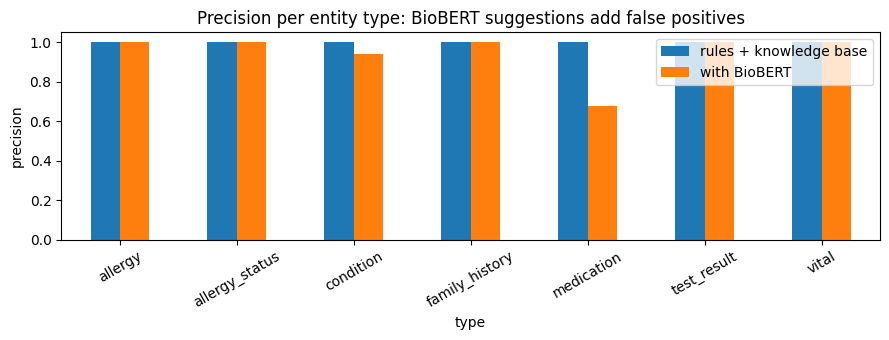

In [5]:
ax = comparison.xs("precision", axis=1, level=1).drop(index="ALL").plot.bar(figsize=(9, 3.5), rot=30)
ax.set_title("Precision per entity type: BioBERT suggestions add false positives")
ax.set_ylim(0, 1.05); ax.set_ylabel("precision"); plt.tight_layout(); plt.show()

**Reading the result.** On the generated set the rules reach 100% because the generator and the extractor were written by the same author: this shows the patterns work as designed, not how they generalise. BioBERT adds recall only for names outside the knowledge base and costs precision (mostly medicines), so it stays a low-confidence "model suggestion" that never creates a flag.

## 3. Negation: confusion matrix for conditions

For conditions found and expected, was "negated" read correctly?

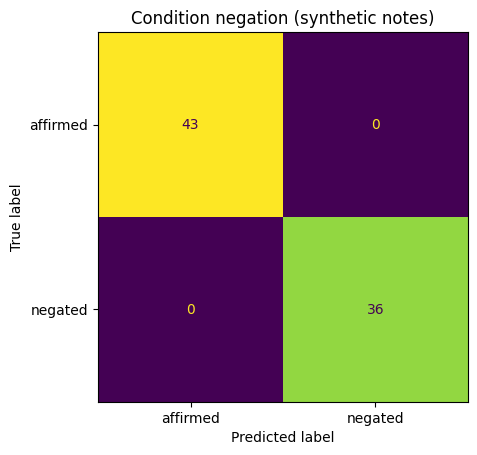

accuracy: 100.0% on 79 conditions


In [6]:
truth_neg, pred_neg = [], []
for r in reports:
    expected = {e["name"]: bool(e.get("negated")) for e in r["entities"] if e["type"] == "condition"}
    for e in extract_entities(r["text"]):
        if e["type"] == "condition" and e["name"] in expected:
            truth_neg.append(expected[e["name"]]); pred_neg.append(bool(e["negated"]))
matrix = confusion_matrix(truth_neg, pred_neg, labels=[False, True])
ConfusionMatrixDisplay(matrix, display_labels=["affirmed", "negated"]).plot(colorbar=False)
plt.title("Condition negation (synthetic notes)"); plt.show()
print(f"accuracy: {sum(t == p for t, p in zip(truth_neg, pred_neg)) / len(truth_neg):.1%} on {len(truth_neg)} conditions")

## 4. The hand-written set (harder phrasing)

Written by hand, with phrasing the generator does not use. Its ground truth was written before the extractor was run on it.

In [7]:
hand = json.loads((ROOT / "scripts" / "icse_bench" / "handwritten.json").read_text(encoding="utf-8"))["reports"]
hand_rows = []
for r in hand:
    expected = Counter(key(e) for e in r["entities"])
    found = Counter(key(e) for e in extract_entities(r["text"]) if e["type"] in TYPES)
    for item in expected | found:
        hand_rows.append({"report": r["id"], "type": item[0], "item": item, "expected": item in expected, "rules": item in found})
hand_frame = pd.DataFrame(hand_rows)
display(metrics(hand_frame, "rules"))
hand_frame[hand_frame["expected"] != hand_frame["rules"]][["report", "item", "expected", "rules"]]

,expected,precision,recall,f1
type,,,,
allergy,3,1.000,1.000,1.000
allergy_status,1,1.000,1.000,1.000
condition,12,0.923,1.000,0.960
family_history,0,0.000,0.000,0.000
medication,10,1.000,1.000,1.000
test_result,12,1.000,0.917,0.957
ALL,38,0.949,0.974,0.961


,report,item,expected,rules
6,hw01,"(family_history, diabetes mellitus)",False,True
7,hw01,"(condition, tuberculosis, True)",False,True
32,hw05,"(test_result, total cholesterol, 240)",True,False


## 5. FE-3: flags from what was read vs from the ground truth

In [8]:
flag_rows = []
for patient, group in pd.DataFrame(reports).groupby("patient"):
    read, truth = [], []
    for index, r in enumerate(group.to_dict("records")):
        found = extract_entities(r["text"])
        read.append({"report_id": index, "date": printed_date(found), "entities": found})
        truth.append({"report_id": index, "date": r["date"], "entities": [truth_entity(e) for e in r["entities"]]})
    expected, got = flag_keys(build_flags(truth)), flag_keys(build_flags(read))
    for item in expected | got:
        flag_rows.append({"patient": patient, "code": item[0], "expected": expected[item], "found": got[item]})
flags = pd.DataFrame(flag_rows)
by_code = flags.groupby("code")[["expected", "found"]].sum()
by_code["agreement"] = (flags.assign(hit=flags[["expected", "found"]].min(axis=1)).groupby("code")["hit"].sum() / by_code["expected"]).round(3)
by_code

,expected,found,agreement
code,,,
CHRONIC_CONDITION,29,29,1.0
HIGH_ALERT_MEDICINE,5,5,1.0
ONGOING_TREATMENT,12,12,1.0
PERSISTENT_HIGH,7,7,1.0
RESULT_HIGH,39,39,1.0
RESULT_LOW,8,8,1.0
TREND_FALLING,2,2,1.0
TREND_RISING,1,1,1.0


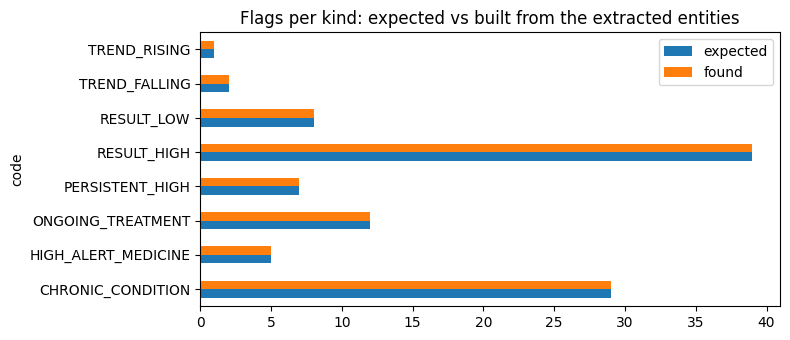

In [9]:
ax = by_code[["expected", "found"]].plot.barh(figsize=(8, 3.5))
ax.set_title("Flags per kind: expected vs built from the extracted entities"); plt.tight_layout(); plt.show()

## 6. OCR: test values read right, wrong or missed

From the OCR benchmark (`scripts/ocr_bench`): `current` is the app before ocr-quality, `app` is the app now (PP-OCRv5 with rows). A wrong value is the dangerous outcome.

text_total  text_correct  text_wrong  rules_total  \
engine  kind                                                           
app     digital           111           111           0           43   
        scan              111           108           0           43   
        scan_hard          45            42           0           18   
current digital           111           111           0           43   
        scan              111            63          41           43   
        scan_hard          45             0          38           18   

                   rules_correct  rules_wrong  
engine  kind                                   
app     digital               43            0  
        scan                  43            0  
        scan_hard             18            0  
current digital               43            0  
        scan                  27           16  
        scan_hard              2           13

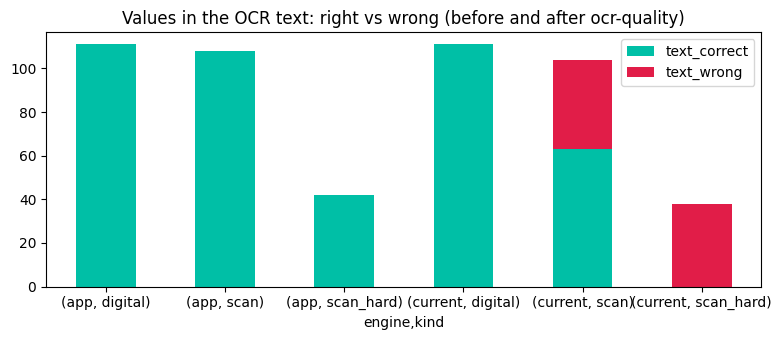

In [10]:
results = ROOT / "ocr_samples" / "_results" / "results.csv"
if results.exists():
    ocr = pd.read_csv(results)
    ocr = ocr[ocr["engine"].isin(["current", "app"])]
    table = ocr.groupby(["engine", "kind"])[["text_total", "text_correct", "text_wrong", "rules_total", "rules_correct", "rules_wrong"]].sum()
    display(table)
    ax = table[["text_correct", "text_wrong"]].plot.bar(stacked=True, figsize=(8, 3.5), rot=0, color=["#00BFA6", "#e11d48"])
    ax.set_title("Values in the OCR text: right vs wrong (before and after ocr-quality)"); plt.tight_layout(); plt.show()
else:
    print("Run scripts/ocr_bench/benchmark.py first to include the OCR results.")

## 7. Conclusions

- **FE-1**: the rules and the knowledge base give traceable entities (every one has a position and a source); BioBERT is kept as a secondary, low-confidence signal because it lowers precision.
- **Negation and family history** are handled by context rules; the remaining known errors are listed in `scripts/icse_bench/RESULTS.md`.
- **FE-3**: flags built from extracted entities match the ground-truth flags; errors would come from reading, not from the rules.
- **OCR**: rebuilding rows removed every wrong number on the synthetic scans; values OCR is unsure of are listed to check, never judged.
- **Limits**: synthetic data written by the same team; a held-out set written independently is still to come.